In [1]:
import xarray as xr
import cartopy.crs as ccrs
from gdf_tools import labels_to_gdf
from scipy.ndimage import label
import matplotlib.pyplot as plt
import cmocean.cm as cmo
import pandas as pd
from gdf_tools import cyclone_buffers
import geopandas as gpd
import numpy as np
from gdf_tools import event_box, cut
from shapely.geometry import box
from tqdm.notebook import tqdm
from polar_events import rain_objects, cyclone_footprints, attribute, merge_by_cyclone, event_boxes, cut
import pandas as pd


In [9]:
precip = xr.open_dataarray('/nird/datapeak/NS12107K/rguilcas/data/tp_daily_winter_2023-2025_Nh_10_90.nc')
mask_land = xr.open_dataarray('/nird/datapeak/NS12107K/rguilcas/data/era5_saeland_mask_Nh_30_80.nc')
climato = xr.open_dataarray('/nird/datapeak/NS12107K/rguilcas/data/ERA5_extreme_precip_climato_DJF_1990_2019_NH.nc')
climato = climato.assign_coords(longitude=climato.longitude.where(climato.longitude<180, climato.longitude-360)).sortby('longitude')

climato_SON = xr.open_dataarray('/nird/datapeak/NS12107K/rguilcas/data/ERA5_extreme_precip_climato_SON_1990_2019_NH.nc')
climato_SON = climato_SON.assign_coords(longitude=climato_SON.longitude.where(climato_SON.longitude<180, climato_SON.longitude-360)).sortby('longitude')

precip = precip.assign_coords(longitude=precip.longitude.where(precip.longitude<180, precip.longitude-360)).sortby('longitude')
mask_land = mask_land.assign_coords(longitude=mask_land.longitude.where(mask_land.longitude<180, mask_land.longitude-360)).sortby('longitude')


In [6]:
from run_one_day import run_one_day
# run_one_day("2024-12-05", precip, climato, mask_land)


In [5]:
date_range_error = pd.to_datetime([
    # "2024-12-01 00:00:00",
    # "2024-12-05 00:00:00",
    "2024-12-06 00:00:00",
    "2024-12-09 00:00:00",
    "2024-12-11 00:00:00",
    "2024-12-13 00:00:00",
    "2024-12-15 00:00:00",
    "2024-12-17 00:00:00",
    "2024-12-19 00:00:00",
    "2024-12-25 00:00:00",
    "2024-12-26 00:00:00",
    "2024-12-28 00:00:00",
    "2024-12-30 00:00:00",
    "2025-01-04 00:00:00",
    "2025-01-06 00:00:00",
    "2025-01-11 00:00:00",
    "2025-01-12 00:00:00",
    "2025-01-15 00:00:00",
    "2025-01-16 00:00:00",
    "2025-01-20 00:00:00",
    "2025-01-24 00:00:00",
    "2025-01-26 00:00:00",
    "2025-01-28 00:00:00",
    "2025-02-02 00:00:00",
    "2025-02-05 00:00:00",
    "2025-02-06 00:00:00",
    "2025-02-07 00:00:00",
    "2025-02-14 00:00:00",
    "2025-02-17 00:00:00",
    "2025-02-18 00:00:00",
    "2025-02-22 00:00:00",
    "2025-02-24 00:00:00",
    "2025-02-26 00:00:00"])

In [10]:
date_range = pd.date_range("2024-09-15", "2024-11-30", freq='1D')
for day in tqdm(date_range):
    try:
        run_one_day(day, precip, climato_SON, mask_land)
    except Exception as e:
        print(f"Error processing day {day}: {e}")

  0%|          | 0/91 [00:00<?, ?it/s]

2024-09-01:   0%|          | 0/112 [00:00<?, ?it/s]

2024-09-02:   0%|          | 0/112 [00:00<?, ?it/s]

2024-09-03:   0%|          | 0/140 [00:00<?, ?it/s]

  2024-09-04 cyclone footprints: types {'Polygon': 11, 'MultiPolygon': 2, 'LineString': 1} -> kept 13 polygonal, dropped 1


...

2024-09-12:   0%|          | 0/168 [00:00<?, ?it/s]

2024-09-13:   0%|          | 0/168 [00:00<?, ?it/s]

  2024-09-14 cyclone footprints: types {'Polygon': 13, 'GeometryCollection': 1, 'MultiPolygon': 1} -> kept 15 polygonal, dropped 0


2024-09-14:   0%|          | 0/140 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
date_range = pd.date_range("2025-09-01", "2025-11-30", freq='1D')
for day in tqdm(date_range):
    try:
        run_one_day(day, precip, climato_SON, mask_land)
    except Exception as e:
        print(f"Error processing day {day}: {e}")

In [ ]:
date_range = pd.date_range("2025-09-01", "2025-11-30", freq='1D')
for day in tqdm(date_range):
    try:
        run_one_day(day, precip, climato_SON, mask_land)
    except Exception as e:
        print(f"Error processing day {day}: {e}")

In [3]:
date_range = pd.date_range("2024-01-01", "2024-02-29", freq='1D')
for day in tqdm(date_range):
    try:
        run_one_day(day, precip, climato, mask_land)
    except Exception as e:
        print(f"Error processing day {day}: {e}")

  0%|          | 0/60 [00:00<?, ?it/s]

Error processing day 2024-01-01 00:00:00: name 'run_one_day' is not defined
Error processing day 2024-01-02 00:00:00: name 'run_one_day' is not defined
Error processing day 2024-01-03 00:00:00: name 'run_one_day' is not defined
Error processing day 2024-01-04 00:00:00: name 'run_one_day' is not defined
Error processing day 2024-01-05 00:00:00: name 'run_one_day' is not defined
Error processing day 2024-01-06 00:00:00: name 'run_one_day' is not defined
Error processing day 2024-01-07 00:00:00: name 'run_one_day' is not defined
Error processing day 2024-01-08 00:00:00: name 'run_one_day' is not defined
Error processing day 2024-01-09 00:00:00: name 'run_one_day' is not defined
Error processing day 2024-01-10 00:00:00: name 'run_one_day' is not defined
Error processing day 2024-01-11 00:00:00: name 'run_one_day' is not defined
Error processing day 2024-01-12 00:00:00: name 'run_one_day' is not defined
Error processing day 2024-01-13 00:00:00: name 'run_one_day' is not defined
Error proces

In [8]:
date_range = pd.date_range("2025-12-01", "2025-12-31", freq='1D')
for day in tqdm(date_range):
    try:
        run_one_day(day, precip, climato, mask_land)
    except Exception as e:
        print(f"Error processing day {day}: {e}")

  0%|          | 0/31 [00:00<?, ?it/s]

  2025-12-01 cyclone footprints: types {'Polygon': 15, 'MultiPolygon': 2, 'GeometryCollection': 1} -> kept 18 polygonal, dropped 0


2025-12-01:   0%|          | 0/84 [00:00<?, ?it/s]

  2025-12-02 cyclone footprints: types {'Polygon': 12, 'MultiPolygon': 2, 'GeometryCollection': 1} -> kept 15 polygonal, dropped 0


2025-12-02:   0%|          | 0/84 [00:00<?, ?it/s]

...

  2025-12-28 cyclone footprints: types {'Polygon': 13, 'Point': 1, 'MultiPolygon': 1} -> kept 14 polygonal, dropped 1


2025-12-28:   0%|          | 0/84 [00:00<?, ?it/s]

  2025-12-29 cyclone footprints: types {'Polygon': 10, 'MultiLineString': 1, 'LineString': 1} -> kept 10 polygonal, dropped 2


2025-12-29:   0%|          | 0/56 [00:00<?, ?it/s]

2025-12-30:   0%|          | 0/56 [00:00<?, ?it/s]

In [43]:
ds =xr.open_dataset('/nird/datapeak/NS12107K/rguilcas/aifs-cyclone-rain-predictions/cyclonic_event_2025-02-01_sid7.nc')

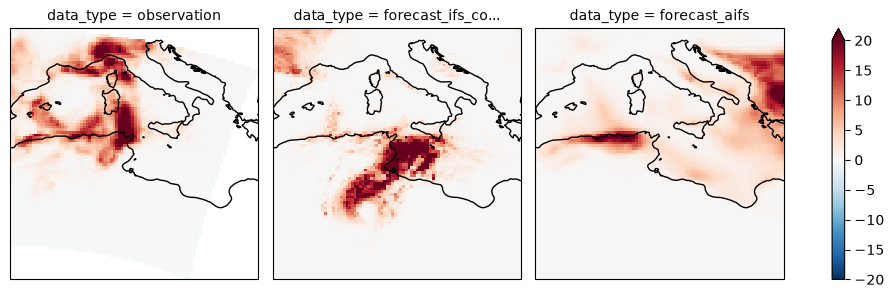

In [55]:


plot = ds[['observation','forecast_ifs_control', 'forecast_aifs']].to_array('data_type').isel(init_time=9).plot(col='data_type',subplot_kws=dict(projection=ccrs.PlateCarree()), transform=ccrs.PlateCarree(), vmax=20)
for ax in plot.axs.flat:
    ax.coastlines()

In [5]:
import dynamical_catalog  # pip install "dynamical-catalog>=0.8.0"

# ds_aifs = dynamical_catalog.open("ecmwf-aifs-single-forecast", chunks=None)
# pr_aifs = ds_aifs["precipitation_surface"].sel(latitude=slice(80,30))#.where(land)  # rate, see units below

In [6]:
OUT_DIR = "/nird/datapeak/NS12107K/rguilcas/aifs-cyclone-rain-predictions"
CYC_DIR = "/nird/datapeak/NS12107K/rguilcas/data/cyclones_cnect"
LEAD_DAYS = np.arange(1, 15)                     # forecasts started 1..14 days before the event day

# open the AIFS archive once, not once per day
_aifs = dynamical_catalog.open("ecmwf-aifs-single-forecast", chunks=None)["precipitation_surface"]
_lat = _aifs.latitude.values
PR_aifs = _aifs.sel(latitude=slice(90, 10) if _lat[0] > _lat[-1] else slice(10, 90))



In [10]:
OUT_DIR = "/nird/datapeak/NS12107K/rguilcas/aifs-cyclone-rain-predictions"
CYC_DIR = "/nird/datapeak/NS12107K/rguilcas/data/cyclones_cnect"
LEAD_DAYS = np.arange(1, 15)                     # forecasts started 1..14 days before the event day

# open the AIFS archive once, not once per day
_ifs = dynamical_catalog.open("ecmwf-ifs-ens-forecast-15-day-0-25-degree", chunks=None)["precipitation_surface"]
# _lat = _aifs.latitude.values
# PR_ifs = _aifs.sel(latitude=slice(90, 10) if _lat[0] > _lat[-1] else slice(10, 90))



In [12]:
print(_ifs.encoding.get("chunks") or _ifs.encoding.get("preferred_chunks"))

(1, 85, 51, 32, 32)


# PART I: detect cyclonic events

In [ ]:
import numpy as np
import pandas as pd
import xarray as xr
import shapely
import dynamical_catalog
from tqdm.notebook import tqdm
from polar_events import (rain_objects, cyclone_footprints, attribute, merge_by_cyclone,
                          event_boxes, cut, TO_POLAR)

OUT_DIR = "/nird/datapeak/NS12107K/rguilcas/aifs-cyclone-rain-predictions"
CYC_DIR = "/nird/datapeak/NS12107K/rguilcas/data/cyclones_cnect"
LEAD_DAYS = np.arange(1, 15)                     # forecasts started 1..14 days before the event day

# open the AIFS archive once, not once per day
_aifs = dynamical_catalog.open("ecmwf-aifs-single-forecast", chunks=None)["precipitation_surface"]
_lat = _aifs.latitude.values
PR_aifs = _aifs.sel(latitude=slice(90, 10) if _lat[0] > _lat[-1] else slice(10, 90))


def standard_grid(a, ndigits=4):
    lat = np.round(a.latitude.values.astype("float64"), ndigits)
    lon = np.round((((a.longitude.values.astype("float64") + 180) % 360) - 180), ndigits)
    return a.assign_coords(latitude=lat, longitude=lon).sortby("latitude", ascending=False).sortby("longitude")


def event_mask(field, geom):
    """True where a cell's centre lies inside the event polygon (polar CRS)."""
    LA, LO = xr.broadcast(field.latitude.reset_coords(drop=True), field.longitude.reset_coords(drop=True))
    X, Y = TO_POLAR.transform(LO.values, LA.values)
    return xr.DataArray(shapely.contains_xy(geom, X, Y), coords=LA.coords, dims=LA.dims)


def load_cyclones(day):
    nxt = day + pd.Timedelta(days=1)
    files = {f"{CYC_DIR}/{t.year}/System13_2E5R_BBox10_{t.year}{t.month:02d}.csv" for t in (day, nxt)}
    cyc = pd.concat([pd.read_csv(f) for f in files])
    cyc["datetime"] = pd.to_datetime(cyc[["year", "month", "day", "hour"]])
    cyc = cyc[(cyc["datetime"] >= day) & (cyc["datetime"] <= nxt)].drop_duplicates()
    return cyc[cyc["lat"] > 20]                  # add track filters here


def run_one_day(day):
    day = pd.Timestamp(day)                       # needed before any date arithmetic

    # --- ERA5: heavy-rain objects, cyclone attribution, event boxes -------------------
    da = precip.sel(time=day)
    thr = climato.sel(quantile=0.95)
    heavy = (da > thr) & (da > 10) & mask_land

    objs = rain_objects(da, heavy, min_area_km2=20000)
    if len(objs) == 0:
        return []

    cyc = load_cyclones(day)
    fp_true = cyclone_footprints(cyc, cyc["radius"], aggfunc={"radius": "max", "depth": "max"})
    objs_true = attribute(objs, fp_true)
    merged = merge_by_cyclone(objs_true)
    if len(merged) == 0:
        return []
    events = event_boxes(merged, min_size_km=2000, margin_km=500)

    obs_boxes = [standard_grid(cut(da, b)) for b in events["box"]]

    # --- AIFS: daily totals (00-24 UTC) for each lead, cut to the same boxes ----------
    fc_boxes = [[] for _ in range(len(events))]
    for lead_d in tqdm(LEAD_DAYS, desc=f"{day:%Y-%m-%d}", leave=False):
        init = day - pd.Timedelta(days=int(lead_d))
        start = day - init
        steps = PR_aifs.sel(init_time=init, lead_time=slice(start + pd.Timedelta(hours=6),
                                                       start + pd.Timedelta(hours=24))).load()
        assert steps.sizes["lead_time"] == 4, f"init {init}: expected 4 steps, got {steps.sizes['lead_time']}"
        daily = standard_grid(steps.sum("lead_time", min_count=4) * 21600.0)
        for k, b in enumerate(events["box"]):
            fc_boxes[k].append(cut(daily, b).expand_dims(init_time=[init])
                               .assign_coords(lead_days=("init_time", [int(lead_d)])))

    # --- one file per event: forecast, observation, event mask -----------------------
    paths = []
    for k, (_, ev) in enumerate(events.iterrows()):
        fc = standard_grid(xr.concat(fc_boxes[k], dim="init_time").sortby("init_time"))
        ob = obs_boxes[k]
        fc, ob = xr.align(fc, ob, join="exact")            # same cells, or an error

        m = event_mask(ob, ev.geometry) & ob.notnull()
        sid = int(ev["sid"])
        depth = fp_true.set_index("sid")["depth"].get(ev["sid"], np.nan)

        out = xr.Dataset({"forecast": fc, "observation": ob, "event_mask": m.astype("int8")})
        out = out.drop_vars(["expver", "ingested_forecast_length", "expected_forecast_length",
                             "spatial_ref", "time", "quantile"], errors="ignore")
        out["forecast"].attrs.update(units="mm day-1", long_name="AIFS daily precipitation (00-24 UTC)")
        out["observation"].attrs.update(units="mm day-1", long_name="ERA5 daily precipitation (00-24 UTC)")
        out["event_mask"].attrs.update(long_name="Heavy-rain event cells (ERA5)", flag_values="0 1")
        out.attrs.update(
            event_day=f"{day:%Y-%m-%d}", sid=sid, cyclone_depth_max=float(depth),
            event_area_km2=float(ev["area_km2"]), n_objects=len(ev["labels"]),
            centre_lat=float(ev["centre_lat"]), centre_lon=float(ev["centre_lon"]),
            overlap_frac_min=float(ev["overlap_frac"]), rain_max=float(ev["rain_max"]),
            box_polar_bounds_m=list(ev["box"].bounds), box_crs="EPSG:6931",
            n_event_cells=int(m.sum()),
        )
        path = f"{OUT_DIR}/cyclonic_event_{day:%Y-%m-%d}_sid{sid}.nc"
        enc = {v: {"zlib": True, "complevel": 4} for v in out.data_vars}
        out.to_netcdf(path, encoding=enc)
        paths.append(path)
    return paths

In [3]:
import dynamical_catalog  # pip install "dynamical-catalog>=0.8.0"

# ds = dynamical_catalog.open("ecmwf-ifs-single-forecast", chunks=None)
dynamical_catalog

<module 'dynamical_catalog' from '/nird/home/rguilcas/robin-env/lib/python3.12/site-packages/dynamical_catalog/__init__.py'>

In [10]:
day = pd.Timestamp("2025-12-30")
run_one_day(day)


2025-12-30:   0%|          | 0/14 [00:00<?, ?it/s]

['/nird/datapeak/NS12107K/rguilcas/aifs-cyclone-rain-predictions/cyclonic_event_2025-12-30_sid594.nc',
 '/nird/datapeak/NS12107K/rguilcas/aifs-cyclone-rain-predictions/cyclonic_event_2025-12-30_sid628.nc']

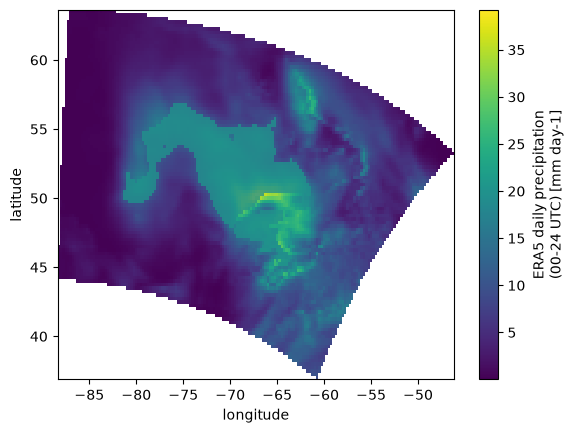

In [21]:
ds = xr.open_dataset('/nird/datapeak/NS12107K/rguilcas/aifs-cyclone-rain-predictions/cyclonic_event_2025-12-30_sid594.nc')
ds.observation.plot()
ds.event_mask.where(ds.event_mask == 1).plot(add_colorbar=False, alpha=.8)

In [169]:

date_range = pd.date_range("2024-12-01", "2025-02-28", freq='1D')
for day in tqdm(date_range):
    try:
        run_one_day(day)
    except Exception as e:
        print(f"Error processing day {day}: {e}")


  0%|          | 0/90 [00:00<?, ?it/s]

  0%|          | 0/13 [00:00<?, ?it/s]

  0%|          | 0/13 [00:00<?, ?it/s]

/tmp/ipykernel_1205233/2100693731.py:99: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  ds.drop('expver').drop('ingested_forecast_length').drop('expected_forecast_length').drop('spatial_ref').to_netcdf(f"/nird/datapeak/NS12107K/rguilcas/aifs-cyclone-rain-predictions/cyclonic_event_{day:%Y-%m-%d}_{k}.nc")


  0%|          | 0/13 [00:00<?, ?it/s]

...

/tmp/ipykernel_1205233/2100693731.py:99: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  ds.drop('expver').drop('ingested_forecast_length').drop('expected_forecast_length').drop('spatial_ref').to_netcdf(f"/nird/datapeak/NS12107K/rguilcas/aifs-cyclone-rain-predictions/cyclonic_event_{day:%Y-%m-%d}_{k}.nc")


  0%|          | 0/13 [00:00<?, ?it/s]

/tmp/ipykernel_1205233/2100693731.py:99: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  ds.drop('expver').drop('ingested_forecast_length').drop('expected_forecast_length').drop('spatial_ref').to_netcdf(f"/nird/datapeak/NS12107K/rguilcas/aifs-cyclone-rain-predictions/cyclonic_event_{day:%Y-%m-%d}_{k}.nc")


  0%|          | 0/13 [00:00<?, ?it/s]

/tmp/ipykernel_1205233/2100693731.py:99: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  ds.drop('expver').drop('ingested_forecast_length').drop('expected_forecast_length').drop('spatial_ref').to_netcdf(f"/nird/datapeak/NS12107K/rguilcas/aifs-cyclone-rain-predictions/cyclonic_event_{day:%Y-%m-%d}_{k}.nc")
/tmp/ipykernel_1205233/2100693731.py:99: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  ds.drop('expver').drop('ingested_forecast_length').drop('expected_forecast_length').drop('spatial_ref').to_netcdf(f"/nird/datapeak/NS12107K/rguilcas/aifs-cyclone-rain-predictions/cyclonic_event_{day:%Y-%m-%d}_{k}.nc")
/tmp/ipykernel_1205233/2100693731.py:99: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  ds.drop('expver').drop('ingested_forecast_length').drop('expected_forecast_length').drop('spatial_ref').to_netcdf(f"/nird/datapeak/NS12107K/rguilcas/aifs-cyclone-rain-predictions/cyclonic_event_{day:%Y-%m

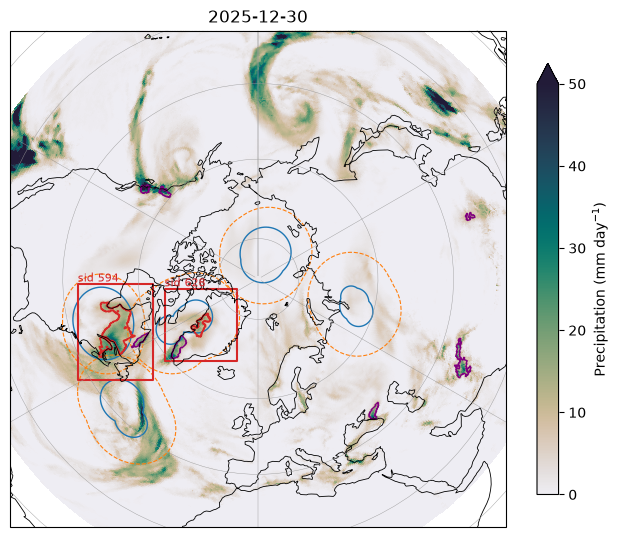

In [92]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import cmocean.cm as cmo

# EASE-Grid 2.0 North (EPSG:6931) as a cartopy projection: same maths as the geometries
POLAR = ccrs.LambertAzimuthalEqualArea(central_longitude=0, central_latitude=90,
                                       globe=ccrs.Globe(ellipse="WGS84"))

def plot_day(da, objs, events, fp_true, fp_fixed=None, vmax=50, lat_min=25):
    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": POLAR})
    ax.set_extent([-180, 180, lat_min, 90], ccrs.PlateCarree())

    im = da.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmo.rain, vmin=0, vmax=vmax,
                 add_colorbar=False)
    fig.colorbar(im, ax=ax, shrink=0.7, extend="max", label="Precipitation (mm day$^{-1}$)")
    ax.coastlines(linewidth=0.6)
    ax.gridlines(linewidth=0.3, color="0.6")

    kw = dict(ax=ax, transform=POLAR, facecolor="none")
    fp_true.plot(edgecolor="tab:blue", linewidth=1, **kw)
    if fp_fixed is not None:
        fp_fixed.plot(edgecolor="tab:orange", linewidth=0.8, linestyle="--", **kw)
    objs[~objs["is_cyclonic"]].plot(edgecolor="purple", linewidth=1, **kw)
    objs[objs["is_cyclonic"]].plot(edgecolor="tab:red", linewidth=1.2, **kw)
    events.set_geometry("box").plot(edgecolor="tab:red", linewidth=1.5, **kw)

    # label each event box with its storm id
    for _, e in events.iterrows():
        x, y = e["box"].bounds[0], e["box"].bounds[3]
        ax.text(x, y, f"sid {int(e['sid'])}", transform=POLAR, fontsize=8,
                color="tab:red", va="bottom")

    ax.set_title(f"{pd.Timestamp(da.time.values):%Y-%m-%d}")
    return fig, ax

fig, ax = plot_day(da, objs_true, events, fp_true, fp_fixed)

In [130]:
save_ds=  [xr.Dataset(dict(forecast=fc_boxes[k], observation=obs_boxes[k])) for k in range(len(fc_boxes))]

for k, ds in enumerate(save_ds):
    ds.drop('expver').drop('ingested_forecast_length').drop('expected_forecast_length').drop('spatial_ref').to_netcdf(f"/nird/datapeak/NS12107K/rguilcas/aifs-cyclone-rain-predictions/cyclonic_event_{day:%Y-%m-%d}_{k}.nc")


# save_ds[0].forecast.attrs#.pop()

/tmp/ipykernel_1205233/4234762148.py:4: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  ds.drop('expver').drop('ingested_forecast_length').drop('expected_forecast_length').drop('spatial_ref').to_netcdf(f"/nird/datapeak/NS12107K/rguilcas/aifs-cyclone-rain-predictions/cyclonic_event_{day:%Y-%m-%d}_{k}.nc")


/tmp/ipykernel_1205233/4234762148.py:4: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  ds.drop('expver').drop('ingested_forecast_length').drop('expected_forecast_length').drop('spatial_ref').to_netcdf(f"/nird/datapeak/NS12107K/rguilcas/aifs-cyclone-rain-predictions/cyclonic_event_{day:%Y-%m-%d}_{k}.nc")


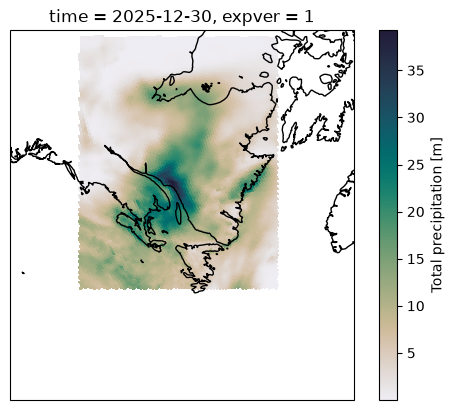

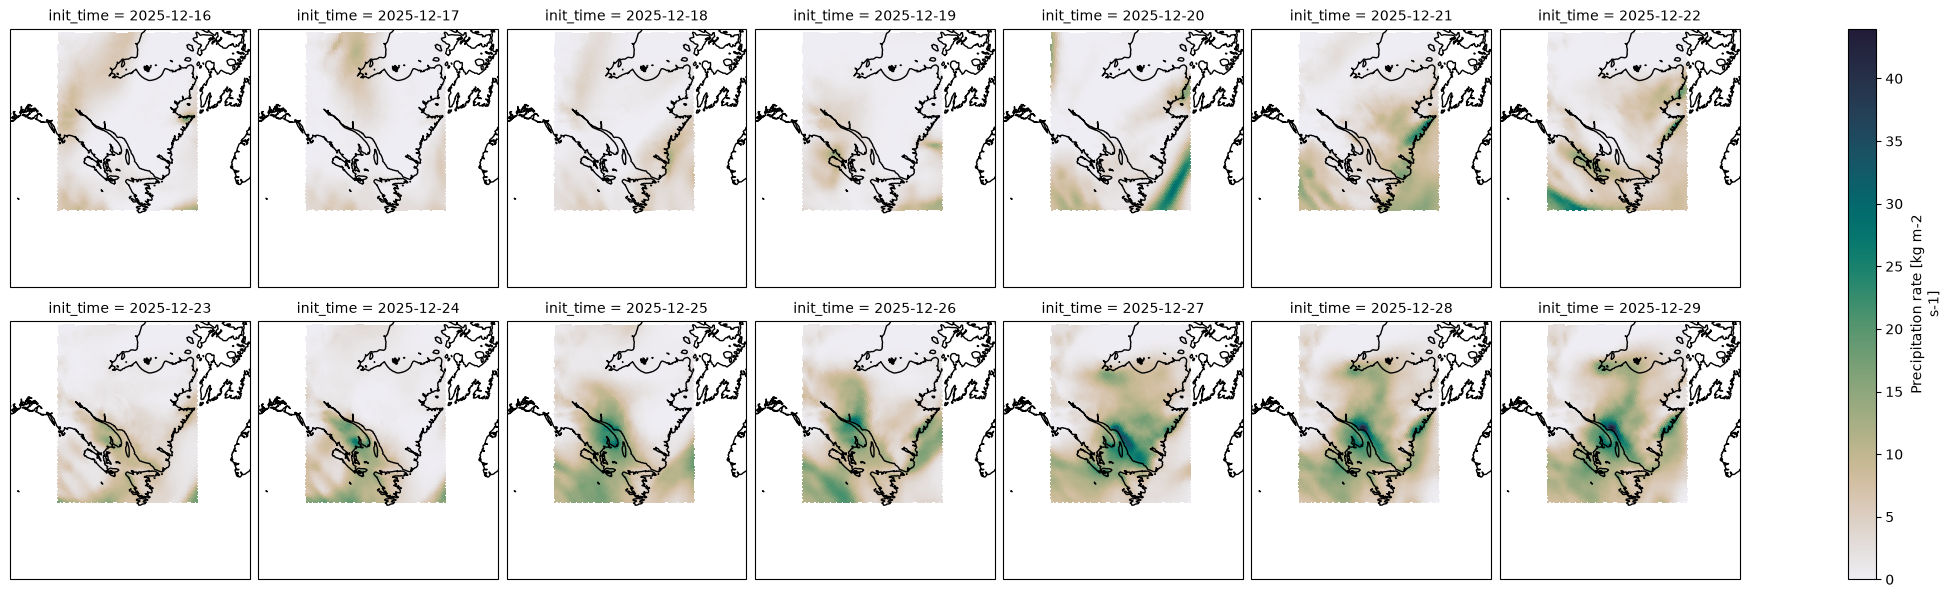

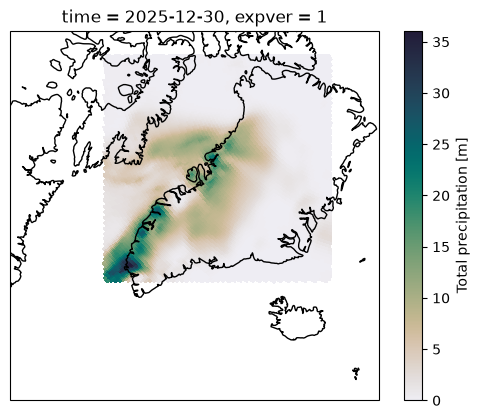

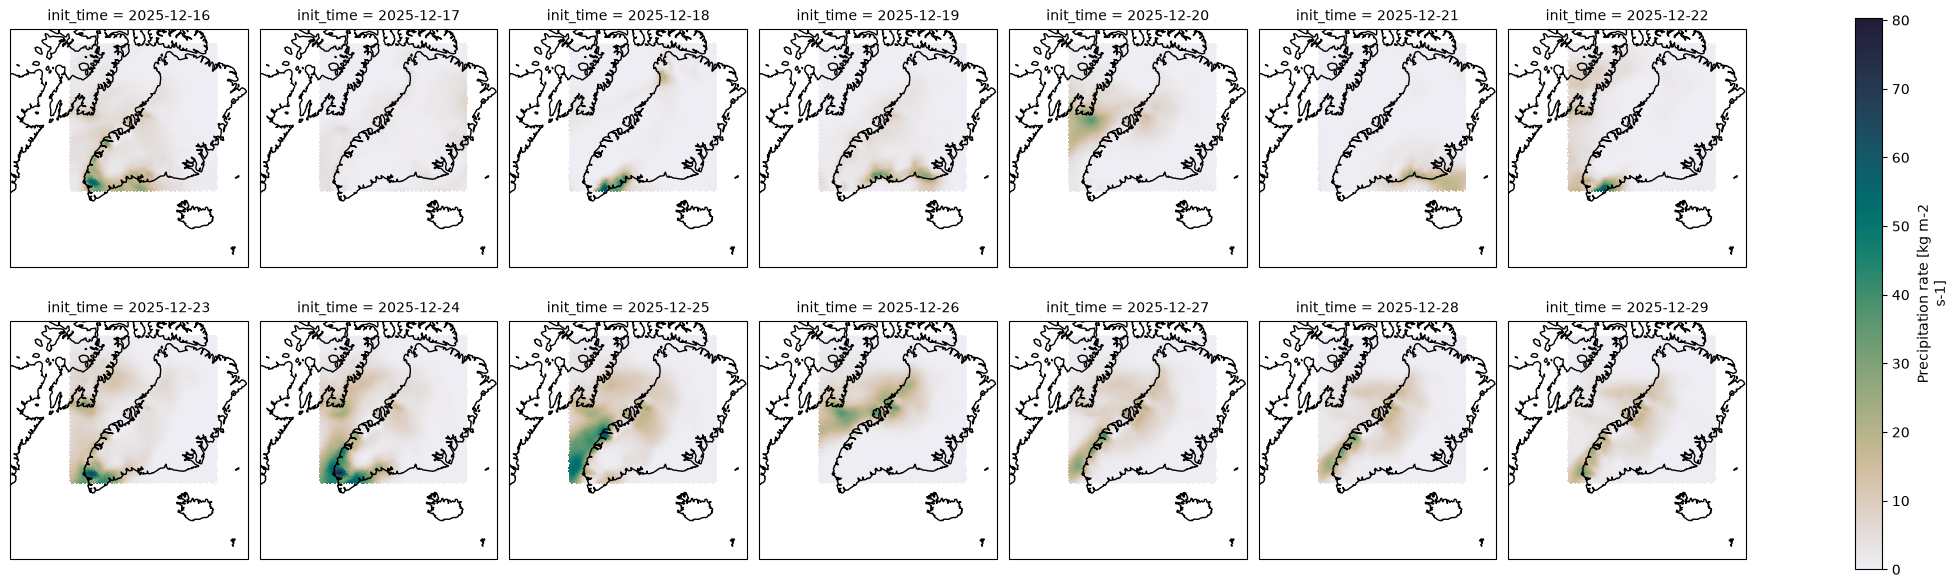

In [100]:
for k in range(len(obs_boxes)):
    fig, ax = plt.subplots(subplot_kw=dict(projection=POLAR))
    obs_boxes[k].plot(cmap=cmo.rain, ax=ax, transform=ccrs.PlateCarree())
    ax.coastlines()
    plot = fc_boxes[k].plot(col='init_time', cmap=cmo.rain,subplot_kws=dict(projection=POLAR), transform=ccrs.PlateCarree(), col_wrap=7)
    for ax in plot.axs.flat:
        ax.coastlines()
        ax.set_extent([fc_boxes[k].longitude.min(), fc_boxes[k].longitude.max(), 
                       fc_boxes[k].latitude.min(), fc_boxes[k].latitude.max()], crs=ccrs.PlateCarree())



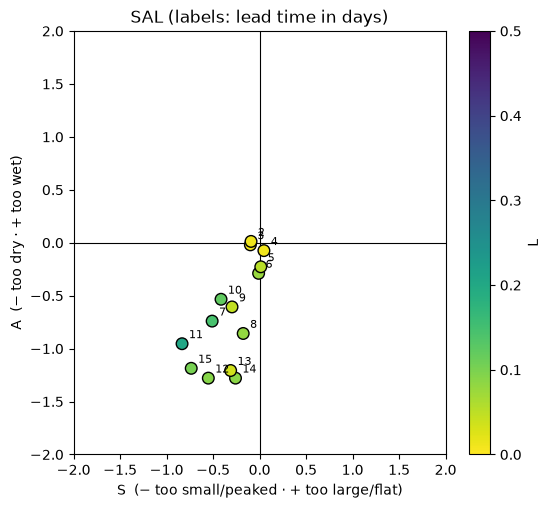

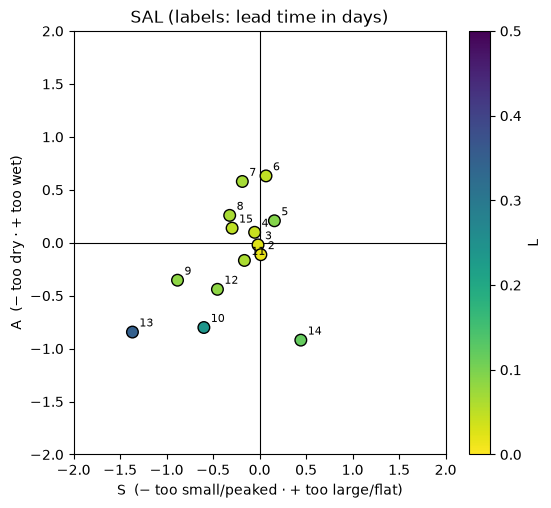

In [101]:
# from event_metrics import event_metrics, plot_event_metrics,plot_sal

for k in range(len(fc_boxes)):
    fc, ob = fc_boxes[k], obs_boxes[k]
    df = event_metrics(fc, ob, event_day=day)
    # plot_event_metrics(df)
    plot_sal(df)

In [5]:
def cut(dataarray, box):
    minx, miny, maxx, maxy = box.bounds
    lat = slice(maxy, miny) if dataarray.latitude[0] > dataarray.latitude[-1] else slice(miny, maxy)
    return dataarray.sel(latitude=lat, longitude=slice(minx, maxx))

In [166]:
gdf_large_rain_cyclone["box"] = gdf_large_rain_cyclone.apply(event_box, axis=1)
boxes = gdf_large_rain_cyclone.set_geometry("box", crs="EPSG:4326")

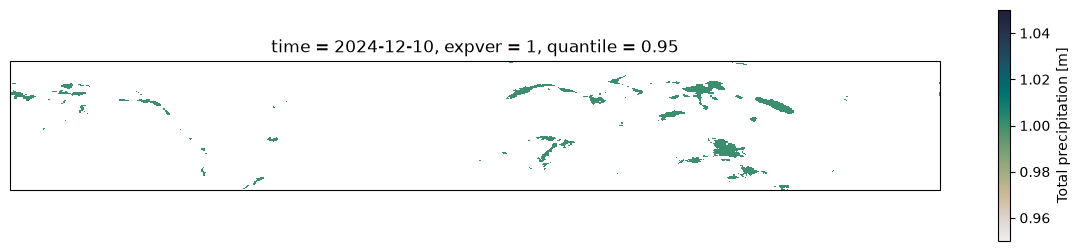

In [37]:
((precip_day-precip_day+1).where(precip_day>climato.sel(quantile=.95))).plot(transform=ccrs.PlateCarree(), subplot_kws=dict(projection=ccrs.PlateCarree()), size=3, aspect=5, cmap=cmo.rain)